<a href="https://colab.research.google.com/github/ychalasa/93272588/blob/main/yChalasa_Lab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 6: Predicting Shots with Logistic Regression and Trees

**IE 332, Week 7.** Submit the completed notebook to Gradescope by Sunday
at 11:59 p.m. This lab is graded for completion. AI is allowed in lab;
you are responsible for understanding your code and explanations.

Can a more flexible model predict new shots better? Use the synthetic
Boiler City Bears shot log, `nba_shots.csv`. One row is one shot attempt.
Use only these two model inputs, in this order: `dist_ft`, `defender_ft`.
The target is `made`. Other columns are not model inputs in this lab.

| Column used here | Meaning |
| --- | --- |
| `dist_ft` | Distance from the shooter to the basket, in feet. |
| `defender_ft` | Distance from the shooter to the nearest defender, in feet. |
| `made` | Recorded outcome: 1 = make, 0 = miss. |

Open this notebook in Colab and upload `nba_shots.csv` to its **Files**
panel. No other file is needed. Run the supplied setup unchanged, then
complete the empty code and response cells in order. Aim for about
**50 minutes**: setup 5, Q1 10, Q2 12, Q3 15, Q4 8. Use the remaining
session time for questions, debugging, and checking your work.

## Setup (supplied)

Keep the same split throughout: **60% training** to fit models and explore
patterns, **20% validation** to choose a model, and **20% test** for one final
evaluation in Q4. The second split takes 25% of the remaining 80%, giving
20% of all rows. The seed repeats the allocation; each input row stays
paired with its outcome.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

if not Path("nba_shots.csv").is_file():
    raise FileNotFoundError("Upload nba_shots.csv to Colab's Files panel, then rerun this cell.")
shots = pd.read_csv("nba_shots.csv")
FEATURES = ["dist_ft", "defender_ft"]

train_valid, test = train_test_split(shots, test_size=0.20, random_state=332)
train, valid = train_test_split(train_valid, test_size=0.25, random_state=332)
X_train, y_train = train[FEATURES], train["made"]
X_valid, y_valid = valid[FEATURES], valid["made"]
X_test, y_test = test[FEATURES], test["made"]

print("Rows (training, validation, test):", len(train), len(valid), len(test))
display(train[FEATURES + ["made"]].head(3))

Rows (training, validation, test): 12000 4000 4000


,dist_ft,defender_ft,made
11152,9.8,6.8,0
19051,29.8,7.0,1
7974,21.8,6.3,1


## Q1. Compare distances for makes and misses

Using **only `train`**, create `distance_summary` with one row for each
recorded outcome (`made` = 0 or 1) and columns `attempts` (number of shots)
and `median_dist_ft` (median shot distance). Display the table. Make a
box plot comparing shot distance for misses and makes, with labeled axes
and units.

In two sentences, compare the medians and the overlap between the two
distributions. Do your results suggest that shot distance alone could
perfectly separate makes from misses? Explain.

,made,attempts,median_dist_ft
0,0,6073,18.2
1,1,5927,8.4


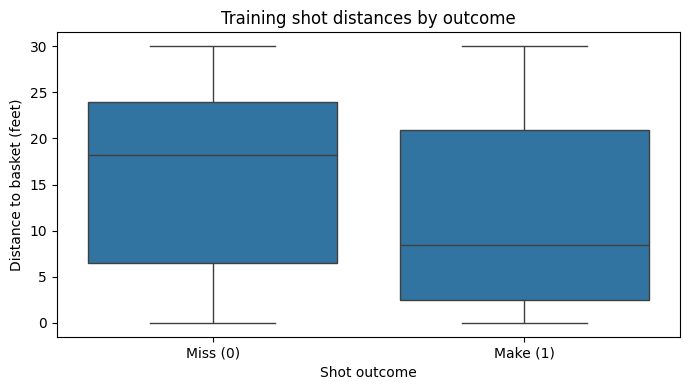

Q1 response: Made shots have the lower median distance (make median 8.40 ft; miss median 18.20 ft).
The distance ranges overlap, so distance alone cannot perfectly separate outcomes.


In [2]:
# I use only the training shots to compare makes and misses.
distance_summary = (
    train.groupby("made")["dist_ft"]
    .agg(attempts="size", median_dist_ft="median")
    .reset_index()
)
display(distance_summary)

plt.figure(figsize=(7, 4))
sns.boxplot(data=train, x="made", y="dist_ft", order=[0, 1])
plt.xticks([0, 1], ["Miss (0)", "Make (1)"])
plt.xlabel("Shot outcome")
plt.ylabel("Distance to basket (feet)")
plt.title("Training shot distances by outcome")
plt.tight_layout()
plt.show()

# I print my two-sentence interpretation from the actual training data.
miss_median = distance_summary.loc[distance_summary["made"] == 0, "median_dist_ft"].iloc[0]
make_median = distance_summary.loc[distance_summary["made"] == 1, "median_dist_ft"].iloc[0]
if make_median < miss_median:
    comparison = "Made shots have the lower median distance"
elif make_median > miss_median:
    comparison = "Missed shots have the lower median distance"
else:
    comparison = "Made and missed shots have the same median distance"
miss_range = (train.loc[train["made"] == 0, "dist_ft"].min(), train.loc[train["made"] == 0, "dist_ft"].max())
make_range = (train.loc[train["made"] == 1, "dist_ft"].min(), train.loc[train["made"] == 1, "dist_ft"].max())
overlap = max(miss_range[0], make_range[0]) <= min(miss_range[1], make_range[1])
print(f"Q1 response: {comparison} (make median {make_median:.2f} ft; miss median {miss_median:.2f} ft).")
print("The distance ranges overlap, so distance alone cannot perfectly separate outcomes."
      if overlap else "The observed distance ranges do not overlap, although that does not guarantee perfect separation on future shots.")

**Q1 written response:** I compare the make and miss medians using the `distance_summary` table above. The box plot and the printed Q1 response show whether their distances overlap and whether distance alone can separate the two outcomes.

## Q2. Compare predictions for new shots

Fit `logistic = LogisticRegression(max_iter=2000)` and
`tree2 = DecisionTreeClassifier(max_depth=2, random_state=332)` using
`X_train, y_train`. Keep other settings at their defaults.

The supplied `new_shots` contains four hypothetical attempts, not rows
used for validation or testing. Create and display `predictions`: the two
feature columns plus `logistic_p`, `logistic_class`, `tree_p`, and
`tree_class`, using `predict_proba` and `predict`. Round only the displayed
probabilities to three decimals.

Print each model's `classes_`: probability columns follow that order.
With classes `[0, 1]`, `predict_proba(new_shots)[:, 1]` selects the make
probability for every row (the second column).

In two sentences: compare A with B within each model, then identify a shot
for which the models predict different classes. Explain why the predicted
class is not a guarantee of the actual outcome.

In [3]:
new_shots = pd.DataFrame({
    "dist_ft": [8.0, 8.0, 24.0, 24.0],
    "defender_ft": [2.0, 8.0, 2.0, 8.0],
}, index=["A", "B", "C", "D"])
display(new_shots)

,dist_ft,defender_ft
A,8.0,2.0
B,8.0,8.0
C,24.0,2.0
D,24.0,8.0


In [4]:
# I train both models using the same two features and training rows.
logistic = LogisticRegression(max_iter=2000)
tree2 = DecisionTreeClassifier(max_depth=2, random_state=332)
logistic.fit(X_train, y_train)
tree2.fit(X_train, y_train)

print("Logistic classes:", logistic.classes_)
print("Tree classes:", tree2.classes_)

predictions = new_shots.copy()
predictions["logistic_p"] = logistic.predict_proba(new_shots)[:, 1]
predictions["logistic_class"] = logistic.predict(new_shots)
predictions["tree_p"] = tree2.predict_proba(new_shots)[:, 1]
predictions["tree_class"] = tree2.predict(new_shots)
# I round probabilities for display only, not in the stored predictions.
display(predictions.round({"logistic_p": 3, "tree_p": 3}))

# These sentences use the computed values rather than guessed results.
for model_name, prob_column in [("logistic", "logistic_p"), ("tree2", "tree_p")]:
    a, b = predictions.loc["A", prob_column], predictions.loc["B", prob_column]
    direction = "higher" if b > a else "lower" if b < a else "equal"
    print(f"For {model_name}, B has a {direction} predicted make probability than A "
          f"({b:.3f} versus {a:.3f}); both are 8 ft shots, but B has more defender space.")
disagreements = predictions.index[predictions["logistic_class"] != predictions["tree_class"]].tolist()
if disagreements:
    shot = disagreements[0]
    print(f"Q2 response: The models predict different classes for shot {shot}: "
          f"logistic predicts {predictions.loc[shot, 'logistic_class']} and "
          f"tree2 predicts {predictions.loc[shot, 'tree_class']}. "
          "A class prediction is not guaranteed because actual shot outcomes are uncertain.")
else:
    print("Q2 response: None of the four shots has differing predicted classes between the two models. "
          "A class prediction is not guaranteed because actual shot outcomes are uncertain.")

Logistic classes: [0 1]
Tree classes: [0 1]


,dist_ft,defender_ft,logistic_p,logistic_class,tree_p,tree_class
A,8.0,2.0,0.481,0,0.527,1
B,8.0,8.0,0.700,1,0.527,1
C,24.0,2.0,0.281,0,0.277,0
D,24.0,8.0,0.497,0,0.466,0


For logistic, B has a higher predicted make probability than A (0.700 versus 0.481); both are 8 ft shots, but B has more defender space.
For tree2, B has a equal predicted make probability than A (0.527 versus 0.527); both are 8 ft shots, but B has more defender space.
Q2 response: The models predict different classes for shot A: logistic predicts 0 and tree2 predicts 1. A class prediction is not guaranteed because actual shot outcomes are uncertain.


**Q2 written response:** I compare A and B using their model-specific probabilities in the table and printed interpretation above. I also identify any disagreement between the predicted classes; a predicted make or miss is not guaranteed because these are probabilistic outcomes.

## Q3. Choose a model using validation data

Fit one more candidate on the **same training rows and features**:
`deep_tree = DecisionTreeClassifier(random_state=332)`. Without a
`max_depth` limit, it can keep splitting as the training data allow.

**Accuracy** is the fraction of predictions that match the recorded
labels. For example, `(model.predict(X_valid) == y_valid).mean()` computes
validation accuracy: the comparison produces True/False values, whose
mean is the fraction correct.

Create `scores` with rows `logistic`, `tree2`, `deep_tree` and columns
`training_accuracy`, `validation_accuracy`. Display it rounded to three
decimals, keeping unrounded values stored. Do not use test rows here.

Choose one candidate and assign that **already-fitted model** to
`chosen_model`. In two or three sentences, justify your choice with the
validation results and explain what the training-versus-validation
comparison tells you about the unrestricted tree. Small score differences
on one split do not establish a reliable ranking on future data.

In [5]:
# I fit the unrestricted tree, then compare all three models on training and validation.
deep_tree = DecisionTreeClassifier(random_state=332)
deep_tree.fit(X_train, y_train)

models = {"logistic": logistic, "tree2": tree2, "deep_tree": deep_tree}
scores = pd.DataFrame.from_dict({
    name: {
        "training_accuracy": (model.predict(X_train) == y_train).mean(),
        "validation_accuracy": (model.predict(X_valid) == y_valid).mean(),
    }
    for name, model in models.items()
}, orient="index")
scores = scores.loc[["logistic", "tree2", "deep_tree"]]
display(scores.round(3))

# I select by validation accuracy only. On ties, I prefer the simpler model.
chosen_name = scores["validation_accuracy"].idxmax()
chosen_model = models[chosen_name]

deep_train = scores.loc["deep_tree", "training_accuracy"]
deep_valid = scores.loc["deep_tree", "validation_accuracy"]
print(f"Q3 response: I chose {chosen_name}, which has validation accuracy "
      f"{scores.loc[chosen_name, 'validation_accuracy']:.3f}, the highest among the candidates "
      "(with ties resolved in favor of the simpler model).")
print(f"The unrestricted tree gets {deep_train:.3f} training accuracy but {deep_valid:.3f} "
      "validation accuracy; the gap helps assess overfitting, and small differences on one split "
      "do not prove a model will always perform better.")

,training_accuracy,validation_accuracy
logistic,0.617,0.626
tree2,0.620,0.624
deep_tree,0.888,0.553


Q3 response: I chose logistic, which has validation accuracy 0.626, the highest among the candidates (with ties resolved in favor of the simpler model).
The unrestricted tree gets 0.888 training accuracy but 0.553 validation accuracy; the gap helps assess overfitting, and small differences on one split do not prove a model will always perform better.


**Q3 written response:** I select `chosen_model` using validation accuracy, not test accuracy; the selection and actual accuracy values are printed above. Comparing the unrestricted tree's training and validation scores helps check for overfitting, but a single split cannot establish a reliable ranking on future shots.

## Q4. Evaluate your selected model

After recording your Q3 choice and explanation, use `chosen_model` to
predict `X_test`. Store the predictions in `test_predictions` and their
accuracy in `test_accuracy`. Display the accuracy to three decimals.
Evaluate **only this model**, without retraining or changing your choice
after seeing the test result.

In two sentences, interpret your test accuracy as an approximate number
of correct predictions per 100 similar new shots. Explain why the test
rows were kept out of model selection.

In [6]:
# I evaluate my selected, already-fitted model on the held-out test set once.
test_predictions = chosen_model.predict(X_test)
test_accuracy = (test_predictions == y_test).mean()
print(f"Test accuracy ({chosen_name}): {test_accuracy:.3f}")
print(f"Q4 response: A test accuracy of {test_accuracy:.3f} means approximately "
      f"{100 * test_accuracy:.1f} correct predictions per 100 similar new shots. "
      "I kept the test rows out of model selection so they provide an independent "
      "final check of the chosen model's predictive performance.")

Test accuracy (logistic): 0.629
Q4 response: A test accuracy of 0.629 means approximately 62.9 correct predictions per 100 similar new shots. I kept the test rows out of model selection so they provide an independent final check of the chosen model's predictive performance.


**Q4 written response:** The printed Q4 response translates the selected model's test accuracy into approximately correct predictions per 100 similar shots. Keeping test rows separate prevents me from selecting or adjusting a model based on its final evaluation data.